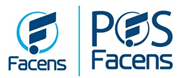 

# <center>Especialização em Ciência dos Dados: Aprendizado de Máquina </center>

Instruções para a realização desta atividade:

1. Faça o download deste notebook Jupyter para sua estação de trabalho
2. Realize as atividades solicitadas dentro do notebook, nos espaços apropriados e indicados
3. Salve o notebook no seguinte padrão: <nome_sobrenome_RA>.ipynb (por exemplo: **rodrigo_caropreso_123456.ipynb ** )
4. Envie o notebook com a atividade realizada na sala de aula da disciplina (Google Classroom)

** DATA DE ENTREGA DESTA ATIVIDADE: 15/12/2018 **

** VALOR DESTA ATIVIDADE: 1,0 ponto **


# <center> Algoritmos Genéticos - Exercício 01 </center>

### Otimização é a procura pelo melhor desempenho em direção a um ou alguns pontos que maximiza(m)/minimiza(m) uma função, ou seja, é a busca da melhor solução para um dado problema.

### O Algoritmo Genético é um algoritmo que realiza esta busca baseado nos mecanismos de evolucionários presentes na natureza, e a preservação das melhores características de adaptação dos indivíduos ao domínio do problema.

### Seu funcionamento básico consiste na análise de aptidão dos indíviduos para a seleção natural daqueles que irão produzir a próxima geração através de cruzamentos. Um mecanismo de mutação garante 'saltos evolucionários' que permitem eventualmente a localização de soluções ainda melhores dentro do espaço de busca.

### Em termos computacionais, o AG possui uma estrutura algorítmica conforme o pseudocódigo a seguir:

//Inicialização – Código em Pseudocódigo do Algoritmo Genético//
1. Gerar uma população inicial.
2. Descartar uma parte dos indivíduos menos aptos (elitismo, roleta, torneio, amostragem universal estocástica)
3. Aplicar operadores de reprodução (crossover)
4. Aplicar operadores de mutação
5. Se o __critério de parada__ foi satisfeito
  >   Então -> encerrar o processo
  
  >   Senão -> volte ao __passo 2__

## Um exemplo simples de otimização é a melhoria da imagem das televisões com antena acoplada. Através do ajuste manual da antena, várias soluções são testadas, guiadas pela qualidade de imagem obtida na TV, até a obtenção de uma resposta ótima, ou seja, uma boa imagem.

## Considere então a seguinte função matemática que representa um sinal de TV:  

<p>
<center>
$
    \large f(x) = x \cdot sen (10 \cdot \pi \cdot x) + 1
$
</center>


## Siga as atividades abaixo e complete o algoritmo AG capaz de otimizar este sinal encontrando seu valor máximo dentro do domínio $ x \in [-1; 2] $

## A função de aptidão f(x) irá variar no intervalo $ y \in [-1; 3] $

# Descrição do indivíduo

## No contexto desta atividade, cada partícula será descrita como um cromossomo de valor binário, capaz de representar um número com 6 casas decimais (22 bits, conforme visto em aula).

### Importando os módulos necessários

In [ ]:
#CÉLULA AG-LIB-01
import numpy as np
import math
import matplotlib.pyplot as plt
from enum import Enum
from operator import xor
%matplotlib inline

class crossoverType(Enum) : 
    OnePoint   = 1
    MultiPoint = 2
    Uniform    = 3 #usa mascara

class selectionType(Enum) : 
    roullete   = 1
    tournament = 2
    stochastic = 3

In [ ]:
#CÉLULA AG-LIB-02
# Plotando o gráfico da função de Fitness
X = np.arange(-1, 2, 0.001)
Y = (X * np.sin(10*np.pi*X) + 1)

plt.figure()
plt.plot(X, Y)
plt.grid()
plt.show()

In [ ]:
#CÉLULA AG-LIB-03
def scale(x1) :
    '''
    Função para cálculo de escalamento e normalização de individuos
    Esta função faz o escalamento de individuos dentro do intervalo [-1, 2]
    22 bits para codificar precisao de 6 digitos
    000000 ... 0 = -1
    111111 ... 1 =  2
    ou seja, x1 em [0, 4194303] -> 2^nbits - 1
    '''
    
    #Teorema de Tales
    # ( x2 - x2_min ) / ( x2_max - x2_min ) = ( x1 - x1_min ) / (x1_max - % x1_min);
    
    #Isolando x2, a variavel de interesse
    # x2 = ( ( x1 - x1_min ) / (x1_max - x1_min) )* ( x2_max - x2_min ) + x2_min;

    x1Min=0
    x1Max=2**22-1
    
    x2Min=-1
    x2Max=2
    
    x2 = ((x1 - x1Min)*(x2Max - x2Min)) / (x1Max - x1Min) + x2Min

    return round(x2, 6)

In [ ]:
#CÉLULA AG-LIB-04
def fitness(individual) :
    '''
    Função para cálculo de fitness (aptidão de cada individuo)

    Parametros
    -----------
    individual  -> cromossomo do individuo cuja aptidao sera calculada
    
    Retorno
    -----------  
    valor da aptidao associada com precisão de 6 casas decimais
    '''
    
    x1 = float(scale(individual))
    result = (x1 * np.sin(10*np.pi*x1) + 1)
    return round(result, 6)

#fitness(0.5)

In [ ]:
#CÉLULA AG-LIB-05
def plot_population(P, generation):
    '''
    Plota em um gráfico a disposição dos indivíduos da população no espaço de busca
    
    Parametros
    -----------
    P          -> array contendo os individuos da população
    generation -> escalar indicando a qual geração do algoritmo está situada a população a ser plotada
    
    Retorno
    -----------  
    N/A
    '''
    
    xmin =-1
    xmax = 2
    ymin =-1
    ymax = 3
    
    xAxis = []
    yAxis = []
    for individual in P :
        xAxis.append(scale(individual))
        yAxis.append(fitness(individual))
    
    plt.figure()
    plt.plot(xAxis, yAxis, 'bo')
    plt.axis([xmin, xmax, ymin, ymax])
    
    plt.xlabel('x')
    plt.ylabel('y')
    sTitle = ('Populacao na geração {}'.format(generation))
    plt.title(sTitle)
    plt.grid()

In [ ]:
#CÉLULA AG-LIB-06
def checkStopCondition(P, stop_condition, epsilon):
    '''
    Verifica a condição de parada do algoritmo genético para uma dada situação
    
    Parametros
    -----------
    P              -> array contendo os individuos da população
    stop_condition -> taxa da população que deve ter convergido para um mesmo local
    epsilon        -> margem de erro aceitável entre valores de aptidão dos cromossomos
    
    Retorno
    -----------  
    True -> se a condição de parada foi atingida, False caso contrário
    '''
    y = [fitness(individual) for individual in P]
    
    if( abs(max(y) - min(y)) < epsilon) :
        print('Todos os individuos convergiram')
        return True
    
    bestIndividuals = [1 for fitness_individual in y if abs(max(y) - fitness_individual) < epsilon]
    #print(len(outliers))
    
    if( (len(bestIndividuals) / len(P)) >= stop_condition) :
        print('Pelo menos {}% de todos os individuos convergiram'.format(stop_condition * 100))
        return True
    
    return False    

In [ ]:
#CÉLULA AG-LIB-07
def roulette(P, vFitness) :
    '''
    Função que efetua o sorteio no estilo roleta entre 0 e aptidacao maxima acumulada
    
    Parametros
    -----------
    P        -> array contendo os individuos da população
    vFitness -> vetor com valores de aptidão alinhado com P
    
    Retorno
    -----------  
    cromossomo vencedor da competição ou -1 em caso de falha
    '''
    maxFitness = sum(vFitness)
    rouletteVal = np.random.rand() * maxFitness
    
    iAcumFitness = 0
    for fitnessVal, index in zip(vFitness, range(0, len(vFitness))):
        iAcumFitness += fitnessVal
        if(iAcumFitness >= rouletteVal) :                
            return P[index]
    
    return -1

In [ ]:
#CÉLULA AG-LIB-08
def tournament(P, vFitness, nCandidates) :
    '''
    Função que realiza o torneio de uma população P. Sorteia nCandidates inidividuos e retorna aquele com maior aptidão
    
    Parametros
    -----------
    P           -> array contendo os individuos da população
    vFitness    -> vetor com valores de aptidão alinhado com P
    nCandidates -> numero de individuos participantes de cada torneio
    
    Retorno
    -----------  
    cromossomo vencedor do torneio
    '''
    v = np.random.randint(0, len(P), size=(nCandidates))
    candidates = [(i, vFitness[i]) for i in v]    
    return P[max(candidates)[0]]

## A amostragem universal estocástica (Stochastic universal sampling) é uma técnica usada em algoritmos genéticos para selecionar indivíduos potencialmente utéis para cruzamento, sendo introduzida por James Baker.

## O SUS constitui-se de uma seleção de aptidão proporcional em intervalos igualmente espaçados, dando uma chance a escolha eventual de indivíduos menos aptos.

## Este método não produz bons resultados se um dado membro da população tiver uma aptidão muito elevada comparada aos demais.


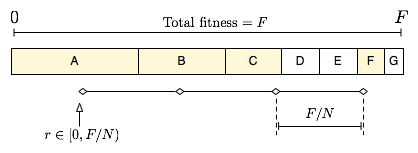

<center> *Figura 1 - SUS. Fonte:* [Wikipedia](https://en.wikipedia.org/wiki/File:Statistically_Uniform.png) </center>



*Pseudocódigo da Amostragem Universal Estocástica*

SUS(**Population, N**)

   **F** := aptidao total da população (**Population**)
   
   **N** := quantidade de agulhas do seletor 
   
   **Step** := distancia entre as agulhas (**F/N**)
   
   **Start** := número aleatório entre 0 e **Start**
   
   **Pointers** := \[**Start** + **i\*Step** | **i** in [0..(**N**-1)]\]
   
   **vWinners** = \[\]
   **for P** in **Pointers**
        **i** := 0
        **while** fitness sum of Population\[0..i\] < P
            **i++**
        add **Population\[i\]** to **vWinners**
      
   return **vWinners**
   
   
*Fonte:* [Wikipedia](https://en.wikipedia.org/wiki/Stochastic_universal_sampling)   

## 1 - Atividade: implemente o código da Amostragem Universal Estocástica, segundo o pseudo-código acima, na função abaixo:

In [ ]:
#CÉLULA AG-LIB-09
def stochasticUniversalSampling(Population, vFitness, N) :
    '''
    Função que realiza a Amostragem Estocástica Universal de uma população P, onde a roleta possui N agulhas.
    
    Parametros
    -----------
    Population-> array contendo os individuos da população
    vFitness  -> vetor com valores de aptidão alinhado com P
    N         -> numero de agulhas da roleta
    
    Retorno
    -----------  
    Vetor contendo os cromossomos vencedores
    '''
    
    vWinners = []
    
    #IMPLEMENTE O CÓDIGO AQUI
    

    
    return vWinners    

In [ ]:
#Teste 


# Teste - use o código abaixo para validar sua implementação


>Population = [100, 200, 300, 400, 500]

>vFitness   = [2, 4, 5, 9, 18]

>vWinners = stochasticUniversalSampling(Population, vFitness, 3)

>print(vWinners)

** Valor esperado: ** Sequencias de individuos do array Population, ex: [300,400,500]. Essas sequencias mudam a cada vez que o código é executado e podem apresentar indivíduos repetidos (por quê?)

In [ ]:
#CÉLULA AG-LIB-10
def selectCandidates(P, method, qty_candidates, sus_qty_pointers) :
    '''
    Função que realiza a seleção dos indivíduos mais aptos de uma população P.
    
    Parametros
    -----------
    P                -> array contendo os individuos da população
    method           -> enumeração que indica o metodo de seleção natural
    qty_candidates   -> quantidade de 'selecionados' a serem retornados pela função
    sus_qty_pointers -> quantidade de agulhas da roleta da amostragem universal estocastica (SUS)
    
    Retorno
    -----------  
    Vetor contendo os cromossomos selecionados
    '''
    candidatesList = []
    
    #Ordena a população em termos de suas aptidões
    #Esta ordenação é necessária para seleção em roleta ou SUS
    vFitness = [fitness(p) for p in P]
    p_tuple = zip(vFitness, P)    
    sorted_by_fitness = sorted(p_tuple, key=lambda tup: tup[0])

    P = []
    vFitnessSorted = []
    for (fitnessValue, p) in sorted_by_fitness :
        P.append(p)
        vFitnessSorted.append(fitnessValue)
    
    if (method == selectionType.roullete) :
        #Deslocaremos a aptidão da população, pois possui valores negativos, assim é possivel calcular o valor acumulado
        vFitnessShifted = [ (2*abs(min(vFitnessSorted)) + x) for x in vFitnessSorted ]                
        
        for _ in range(0, qty_candidates) :
            winner = roulette(P, vFitnessShifted)
            if(winner != -1) :
                candidatesList.append(winner)
        
    elif (method == selectionType.tournament) :
        #Torneio
        for _ in range(0, qty_candidates) :
            winner = tournament(P, vFitnessSorted, 3)
            candidatesList.append(winner)
    else : 
        #Amostragem Universal Estocastica - é uma roleta com multiplos ponteiros (sus_qty_pointers)
        #Deslocaremos a aptidão da população, pois possui valores negativos, assim é possivel calcular o valor acumulado
        vFitnessShifted = [ (2*abs(min(vFitnessSorted)) + x) for x in vFitnessSorted ]                

        vWinners = []
        vWinners = stochasticUniversalSampling(P, vFitnessShifted, sus_qty_pointers)
        for winner in vWinners : 
            candidatesList.append(winner)
        
    return candidatesList

In [ ]:
#CÉLULA AG-LIB-11
def crossover(candidatesList, reproduction_rate, populationSize, mode, crossoverMask) :
    '''
    Função que realiza o cruzamento dos indivíduos mais aptos de uma população P.
    
    Parametros
    -----------
    candidatesList    -> lista de individuos mais aptos
    reproduction_rate -> probabilidade de ocorrer um crossover
    populationSize    -> tamanho esperado da populacao apos o crossover
    mode              -> enumeration que indica o tipo de cruzamento (um ponto, multi-ponto, com mascara)
    mask              -> mascara para crossover do tipo 'uniforme'
    
    Retorno
    -----------  
    Vetor contendo a nova geração de cromossomos após os cruzamentos
    '''
    childrenList = []
    
    for i in range(0, int(populationSize / 2)) :
        #escolhe dois individuos ao acaso
        v = np.random.randint(0, len(candidatesList), size=(2))
        
        p1 = candidatesList[v[0]]
        p2 = candidatesList[v[1]]

        #decide se vai ocorrer reproducao, caso contrario, os filhos serao apenas copias dos pais
        if (np.random.rand() <= reproduction_rate ) :
            if (mode == crossoverType.OnePoint) :                
                #Crossover em um ponto, na metade do cromossomo                
                p1Bin = "{0:022b}".format(p1) #formata numero em 22 bits
                p2Bin = "{0:022b}".format(p2) #formata numero em 22 bits

                #Faz o slice
                geneP1L = p1Bin[0:11]
                geneP1R = p1Bin[11:22]
                
                geneP2L = p2Bin[0:11]
                geneP2R = p2Bin[11:22]
                
                #Realiza o cruzamento, concatena os genes e converte para numero inteiro
                c1 = int(geneP1L+geneP2R, 2) 
                c2 = int(geneP2L+geneP1R, 2)
                
                #Adiciona ao array de filhos
                childrenList.append(c1)
                childrenList.append(c2)
            elif(mode == crossoverType.MultiPoint) :
                #Crossover multi-ponto, realizado na posicao 8 e 16
                p1Bin = "{0:022b}".format(p1) #formata numero em 22 bits
                p2Bin = "{0:022b}".format(p2) #formata numero em 22 bits

                #Slicing
                geneP1L = p1Bin[0:8]
                geneP1M = p1Bin[8:16]
                geneP1R = p1Bin[16:22]
                
                geneP2L = p2Bin[0:8]
                geneP2M = p2Bin[8:16]
                geneP2R = p2Bin[16:22]

                #Realiza o cruzamento, trocando somente a parte do meio, concatena os genes e converte para numero inteiro
                c1 = int(geneP1L + geneP2M + geneP1R, 2) 
                c2 = int(geneP2L + geneP1M + geneP2R, 2)
                
                #Adiciona ao array de filhos
                childrenList.append(c1)
                childrenList.append(c2)                
            else:
                #Usa a mascara fornecida e realiza um OU-Exclusivo
                #'0b' será necessario para o XOR
                p1Bin = '0b' + "{0:022b}".format(p1) #formata numero em 22 bits
                p2Bin = '0b' + "{0:022b}".format(p2) #formata numero em 22 bits

                #Realiza cruzamento
                c1 = int(p1Bin,2) ^ crossoverMask
                c2 = int(p2Bin,2) ^ crossoverMask
                
                #Adiciona ao array de filhos
                childrenList.append(c1)
                childrenList.append(c2)
        else:
            # Não ocorreu reprodução, os filhos são copias dos pais
            childrenList.append(p1)
            childrenList.append(p2)
    
    return childrenList

In [ ]:
#CÉLULA AG-LIB-12
def mutation(candidatesList, mutation_rate) :
    '''
    Função que realiza a mutação dos indivíduos após a realização do crossover de uma população P. 
    Cada indivíduo tem uma probabilidade igual a 'mutation_rate' de sofrer uma mutação em seus genes.
    
    Parametros
    -----------
    candidatesList    -> lista de individuos mais aptos
    mutation_rate     -> probabilidade de ocorrer uma mutação
    
    Retorno
    -----------  
    Vetor contendo a nova geração de cromossomos após as mutações
    '''    
    mutatedList = []
    
    for p in candidatesList :
        if (np.random.rand() <= mutation_rate ) :
            #realiza mutação
            pBin = list("{0:022b}".format(p)) #formata numero em 22 bits

            #sorteia um bit para sofrer mutação
            mutationIndex = np.random.randint(0,len(pBin))
            
            #Aplica mutação
            if (pBin[mutationIndex] == '0') :
                pBin[mutationIndex] = '1'
            else:
                pBin[mutationIndex] = '0'

            #Transforma pBin (lista) em string e a seguir, em inteiro
            pBinStr = ''.join(pBin)
            mutatedList.append(int(pBinStr, 2))
        
        else:
            mutatedList.append(p)
    
    return mutatedList

# Algoritmo Genetico - inicio

In [ ]:
# CÉLULA AG-MAIN-01
#Parâmetros
size_pop          = 100
max_generations   = 100
stop_condition    = 0.95
reproduction_rate = 0.7
mutation_rate     = 0.01

min_individual = 0
max_individual = 2**22-1
sus_qty_pointers = 4 #quantidade de ponteiros da roleta do tipo SUS
crossoverMask = '0b0000111100001111000111' #mascara para crossover

In [ ]:
# CÉLULA AG-MAIN-02
#Inicializando população
P=[]

P = np.random.randint(0, max_individual, size=(size_pop))
P = P.tolist()

In [ ]:
# CÉLULA AG-MAIN-03
plot_population(P, 1)
print(P)

In [ ]:
# CÉLULA AG-MAIN-04
#Loop principal
generation_index = 0
while( generation_index != max_generations) : 
    generation_index = generation_index + 1
            
    if(generation_index % 2 == 0) :
        plot_population(P, generation_index)
    
    stop = checkStopCondition(P, stop_condition, 0.000001)
    if(stop == True) :
        print('Convergencia atingida')
        break
    
    #Selecionando os mais aptos para cruzamento (50% da população)
    candidatesList = []
    candidatesList = selectCandidates(P, selectionType.tournament, int(size_pop / 2), sus_qty_pointers)
        
    #Realiza cruzamento
    childrenList = []
    childrenList = crossover(candidatesList, reproduction_rate, size_pop, crossoverType.OnePoint, crossoverMask)

    #Realiza mutação
    childrenList = mutation(childrenList, mutation_rate)

    #Compõe a população para a proxima geração
    P.clear
    P = childrenList
    
print(len(childrenList))
print(childrenList)
print(generation_index)

In [ ]:
# CÉLULA AG-MAIN-05
#Verificando os resultados

bestFitness    = fitness(childrenList[0])
bestIndividual = childrenList[0]
for p in childrenList :
    if(fitness(p) >= bestFitness) :
        bestFitness = fitness(p)
        bestIndividual = p

print('A convergencia foi atingida na geração: {}'.format(generation_index))
print('O cromossomo vencedor foi: {}->({})b, ou seja, x={} com aptidão {}'.format(bestIndividual, "{0:022b}".format(p), scale(bestIndividual), bestFitness))
print('A solução do problema é x={}'.format(scale(bestIndividual)))

plot_population(P, generation_index)

## 2 - Execute o AG para três cenários:

    1. Seleção natural por roleta
    2. Seleção natural por torneio com 3 indíviduos
    3. Seleção natural por Amostragem Universal Estocástica

Apresente seus comentários sobre o comportamento da convergência da solução.

**RESPOSTA**:

## 3 - Aumente a taxa de mutação e explique o que ocorre no AG.

**RESPOSTA:**

## 4 - Reduza a taxa de crossover para um valor muito baixo e explique o que ocorre no AG.

**RESPOSTA:**